JS01 Tugas Pendahuluan JS02 - kumpulkan 30 data teman, rangkum sebagai spreadsheet.

Data teman sungguhan tidak tersedia untuk agen otomatis, jadi script ini
MEMBANGKITKAN 30 baris data SIMULASI dengan skema kolom persis seperti modul
(nama, jenis kelamin, kota asal, tinggi, berat, asal kelas, target IPS) dan
menyimpannya sebagai CSV. Ganti file CSV-nya dengan data asli, script tetap jalan.

Output: data/tugas_pendahuluan_js02.csv, tugas/output/03_ringkasan.csv,
        tugas/output/03_distribusi.png, tugas/output/04_hubungan.png

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("tugas_pendahuluan_js02.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js01-pengenalan-pembelajaran-mesin\tugas


In [2]:
from pathlib import Path

import matplotlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BASE = Path(__file__).resolve().parent
DATA = BASE.parent / "data"
OUT = BASE / "output"
DATA.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42

In [3]:
# --- 1. Bangkitkan 30 baris (data simulasi, deterministik) -------------------
rng = np.random.default_rng(SEED)

nama_L = [
    "Rizky", "Bagas", "Dimas", "Fajar", "Hendra", "Joko", "Lukman", "Naufal",
    "Putra", "Sandi", "Umar", "Wahyu", "Zaki", "Bayu", "Farhan", "Agus",
]
nama_P = [
    "Anisa", "Citra", "Eka", "Gita", "Intan", "Kartika", "Maya", "Oktavia",
    "Rani", "Tiara", "Vina", "Yuni", "Ayu", "Dewi", "Sari", "Nadia",
]
nama_belakang = [
    "Pratama", "Wulandari", "Santoso", "Maharani", "Saputra", "Lestari", "Hidayat",
    "Permata", "Kurniawan", "Anggraini", "Firmansyah", "Rahmawati", "Nugroho",
    "Safitri", "Ramadhan", "Handayani", "Wijaya", "Oktaviani", "Setiawan",
    "Puspita", "Hakim", "Mulyani", "Syahputra", "Rohmah", "Fauzi", "Nuraini",
    "Susanto", "Kusuma", "Maulana", "Ramadhani",
]
kota = ["Malang", "Kediri", "Blitar", "Pasuruan", "Probolinggo", "Surabaya",
        "Jember", "Madiun", "Tulungagung", "Sidoarjo"]
bobot_kota = [0.30, 0.15, 0.10, 0.10, 0.08, 0.08, 0.07, 0.05, 0.04, 0.03]
kelas = ["TI-1A", "TI-1B", "TI-1C", "TI-1D"]

n = 30
jk = rng.choice(["L", "P"], size=n, p=[0.53, 0.47])
# tinggi/berat dibangkitkan per jenis kelamin supaya distribusinya masuk akal
tinggi = np.where(jk == "L", rng.normal(170.0, 5.5, n), rng.normal(158.0, 5.0, n)).round(1)
bmi_target = rng.normal(21.5, 2.8, n)
berat = (bmi_target * (tinggi / 100) ** 2).round(1)
target_ips = np.clip(rng.normal(3.45, 0.22, n), 2.75, 4.00).round(2)

df = pd.DataFrame({
    "nama_lengkap": [
        f"{rng.choice(nama_L if g == 'L' else nama_P)} {rng.choice(nama_belakang)}"
        for g in jk
    ],
    "jenis_kelamin": jk,
    "kota_asal": rng.choice(kota, size=n, p=bobot_kota),
    "tinggi_cm": tinggi,
    "berat_kg": berat,
    "asal_kelas": rng.choice(kelas, size=n),
    "target_ips": target_ips,
})
df.insert(0, "no", np.arange(1, n + 1))
df["imt"] = (df["berat_kg"] / (df["tinggi_cm"] / 100) ** 2).round(2)

csv_path = DATA / "tugas_pendahuluan_js02.csv"
df.to_csv(csv_path, index=False)

print("=" * 74)
print("JS01 / Tugas Pendahuluan JS02 - 30 data teman (SIMULASI, seed=42)")
print("=" * 74)
print(df.head(8).to_string(index=False))
print(f"... ({len(df)} baris total)")

JS01 / Tugas Pendahuluan JS02 - 30 data teman (SIMULASI, seed=42)
 no     nama_lengkap jenis_kelamin   kota_asal  tinggi_cm  berat_kg asal_kelas  target_ips   imt
  1     Rani Saputra             P      Blitar      149.6      52.3      TI-1B        3.22 23.37
  2    Hendra Wijaya             L      Kediri      167.8      59.8      TI-1A        3.49 21.24
  3 Kartika Maharani             P    Surabaya      158.8      51.2      TI-1D        3.50 20.30
  4       Vina Hakim             P Probolinggo      160.9      55.1      TI-1D        3.75 21.28
  5  Bagas Kurniawan             L      Kediri      173.4      50.4      TI-1A        3.63 16.76
  6     Gita Puspita             P      Malang      162.0      45.8      TI-1C        3.53 17.45
  7     Yuni Mulyani             P    Surabaya      156.3      43.5      TI-1A        3.77 17.81
  8     Nadia Rohmah             P      Malang      155.7      45.4      TI-1C        3.19 18.73
... (30 baris total)


In [4]:
# --- 2. Rangkuman angka ------------------------------------------------------
print("\n[1] Statistik tinggi & berat per jenis kelamin")
ringkas = df.groupby("jenis_kelamin")[["tinggi_cm", "berat_kg", "imt", "target_ips"]].agg(
    ["count", "mean", "std", "min", "max"]
).round(2)
print(ringkas.to_string())

print("\n[2] Sebaran kota asal")
kota_count = df["kota_asal"].value_counts()
print(kota_count.to_string())

print("\n[3] Sebaran asal kelas & target IPS")
per_kelas = df.groupby("asal_kelas")["target_ips"].agg(["count", "mean"]).round(3)
print(per_kelas.to_string())

print("\n[4] Korelasi antar variabel numerik")
num = df[["tinggi_cm", "berat_kg", "imt", "target_ips"]]
print(num.corr().round(3).to_string())


[1] Statistik tinggi & berat per jenis kelamin
              tinggi_cm                             berat_kg                            imt                            target_ips                        
                  count    mean   std    min    max    count   mean   std   min   max count   mean   std    min    max      count  mean   std   min   max
jenis_kelamin                                                                                                                                            
L                    13  170.72  3.87  165.2  178.2       13  60.95  5.68  50.4  70.9    13  20.95  2.21  16.76  25.98         13  3.39  0.17  3.13  3.68
P                    17  156.93  3.65  149.6  162.0       17  50.70  6.51  40.8  61.9    17  20.59  2.55  16.66  25.13         17  3.49  0.27  2.98  4.00

[2] Sebaran kota asal
kota_asal
Malang         12
Blitar          3
Kediri          3
Surabaya        3
Probolinggo     3
Jember          2
Pasuruan        2
Tulungagung     1
Sidoa

In [5]:
# simpan ringkasan sebagai tabel lebar (mudah dibuka di spreadsheet)
ringkas_wide = ringkas.copy()
ringkas_wide.columns = [f"{a}_{b}" for a, b in ringkas_wide.columns]
ringkas_wide.insert(0, "kelompok", "jk=" + ringkas_wide.index)
ringkas_wide.to_csv(OUT / "03_ringkasan.csv", index=False)
print(f"\nringkasan -> {(OUT / '03_ringkasan.csv').name}")


ringkasan -> 03_ringkasan.csv


grafik    -> 03_distribusi.png, 04_hubungan.png

SELESAI: 30 data tersimpan, siap dipakai di JS02.


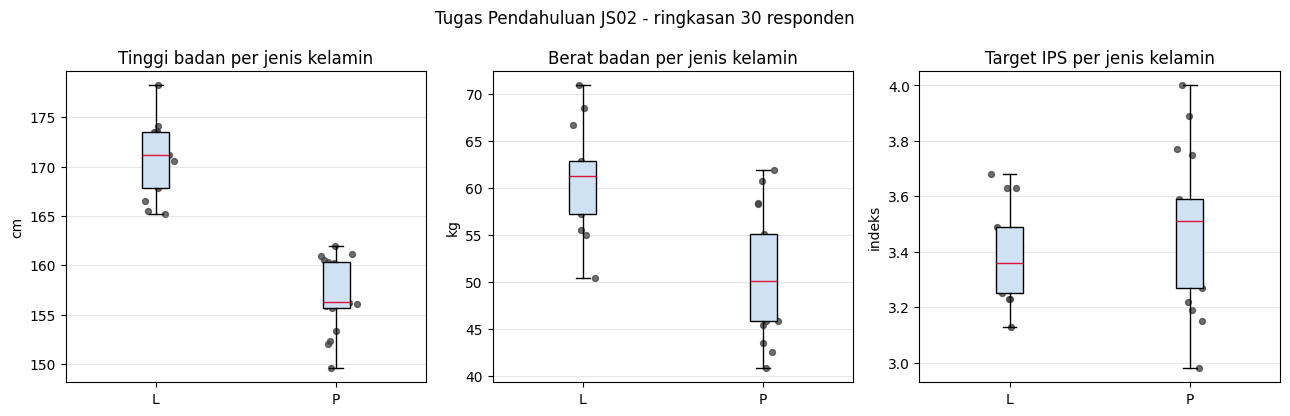

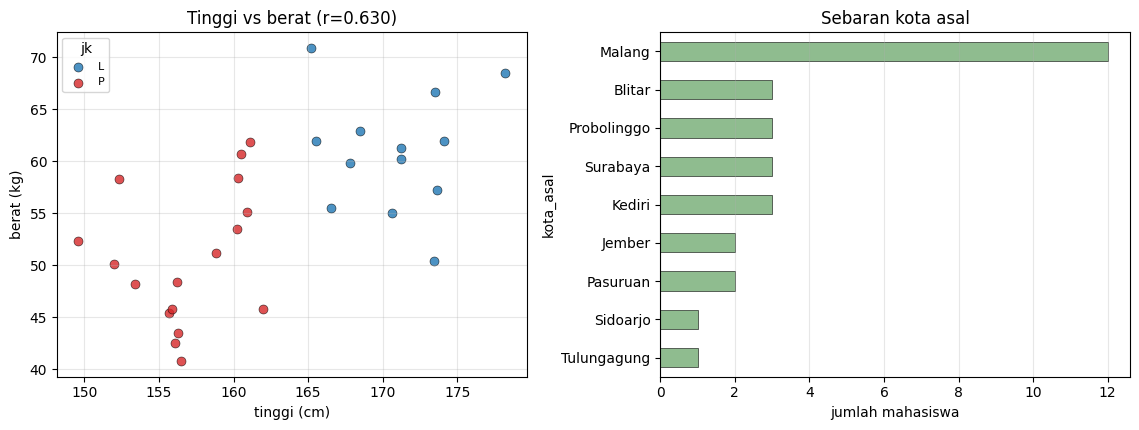

In [6]:
# --- 3. Grafik ---------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, kol, judul, satuan in [
    (axes[0], "tinggi_cm", "Tinggi badan", "cm"),
    (axes[1], "berat_kg", "Berat badan", "kg"),
    (axes[2], "target_ips", "Target IPS", "indeks"),
]:
    data = [df.loc[df.jenis_kelamin == g, kol] for g in ("L", "P")]
    ax.boxplot(data, tick_labels=["L", "P"], patch_artist=True,
               boxprops=dict(facecolor="#cfe2f3"), medianprops=dict(color="crimson"))
    for i, d in enumerate(data, start=1):
        ax.scatter(np.full(d.size, i) + rng.normal(0, 0.04, d.size), d,
                   s=18, color="0.25", alpha=0.75)
    ax.set_title(f"{judul} per jenis kelamin")
    ax.set_ylabel(satuan)
    ax.grid(alpha=0.3, axis="y")
fig.suptitle("Tugas Pendahuluan JS02 - ringkasan 30 responden", fontsize=12)
fig.tight_layout()
fig.savefig(OUT / "03_distribusi.png", dpi=130)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
ax = axes[0]
for g, warna in (("L", "tab:blue"), ("P", "tab:red")):
    sub = df[df.jenis_kelamin == g]
    ax.scatter(sub.tinggi_cm, sub.berat_kg, s=42, alpha=0.8, label=g, color=warna,
               edgecolor="k", linewidth=0.4)
ax.set_xlabel("tinggi (cm)")
ax.set_ylabel("berat (kg)")
ax.set_title(f"Tinggi vs berat (r={df.tinggi_cm.corr(df.berat_kg):.3f})")
ax.legend(title="jk", fontsize=8)
ax.grid(alpha=0.3)

ax = axes[1]
kota_count.sort_values().plot.barh(ax=ax, color="#8fbc8f", edgecolor="k", linewidth=0.4)
ax.set_xlabel("jumlah mahasiswa")
ax.set_title("Sebaran kota asal")
ax.grid(alpha=0.3, axis="x")
fig.tight_layout()
fig.savefig(OUT / "04_hubungan.png", dpi=130)
print(f"grafik    -> 03_distribusi.png, 04_hubungan.png")

assert len(df) == 30
assert df.notna().all().all()
assert df.jenis_kelamin.isin(["L", "P"]).all()
assert (df.target_ips.between(2.75, 4.0)).all()
print("\nSELESAI: 30 data tersimpan, siap dipakai di JS02.")